In [28]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image
import cv2

In [6]:
from pathlib import Path
import sys

# Make imports work whether Jupyter starts in the project root or notebooks/.
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "data" / "data_loader.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.data_loader import load_cub_dataset


d:\Semester 7\Deep Learning\Multimodal_DL_Project\from-pixels-to-language\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
train_dataset, test_dataset = load_cub_dataset()

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 5994
Test samples: 5794


In [8]:
print("Training columns:")
print(train_dataset.column_names)

print("\nTraining features:")
print(train_dataset.features)

print("\nFirst training record:")
print(train_dataset[0])

Training columns:
['image', 'description', 'label', 'file_name', 'id']

Training features:
{'image': Image(mode=None, decode=True), 'description': Value('string'), 'label': ClassLabel(names=['Black footed Albatross', 'Laysan Albatross', 'Sooty Albatross', 'Groove billed Ani', 'Crested Auklet', 'Least Auklet', 'Parakeet Auklet', 'Rhinoceros Auklet', 'Brewer Blackbird', 'Red winged Blackbird', 'Rusty Blackbird', 'Yellow headed Blackbird', 'Bobolink', 'Indigo Bunting', 'Lazuli Bunting', 'Painted Bunting', 'Cardinal', 'Spotted Catbird', 'Gray Catbird', 'Yellow breasted Chat', 'Eastern Towhee', 'Chuck will Widow', 'Brandt Cormorant', 'Red faced Cormorant', 'Pelagic Cormorant', 'Bronzed Cowbird', 'Shiny Cowbird', 'Brown Creeper', 'American Crow', 'Fish Crow', 'Black billed Cuckoo', 'Mangrove Cuckoo', 'Yellow billed Cuckoo', 'Gray crowned Rosy Finch', 'Purple Finch', 'Northern Flicker', 'Acadian Flycatcher', 'Great Crested Flycatcher', 'Least Flycatcher', 'Olive sided Flycatcher', 'Scissor ta

In [9]:
for i in range(min(5, len(train_dataset))):
    sample = train_dataset[i]

    print(f"\nSample {i + 1}")
    for column, value in sample.items():
        if column == "image":
            print(column, ":", type(value))
        else:
            print(column, ":", repr(value)[:500])


Sample 1
image : <class 'PIL.JpegImagePlugin.JpegImageFile'>
description : 'this bird is brown with a lighter brown crest.\naquatic large bird with long hooked bill, white face, and brown body.\nbird has brown body feathers, brown breast feathers, and brown beak\nthis bird has a white superciliary and brown all around its body with a long bill\nthis is a brown bird with a white face and a long downward pointing beak.\nthis bird is brown with white and has a long, pointy beak.\nbrown duck playing on the lake making a poodle\nthis bird has wings that are brown and has a 
label : 0
file_name : 'Black_Footed_Albatross_0007_796138.jpg'
id : 0

Sample 2
image : <class 'PIL.JpegImagePlugin.JpegImageFile'>
description : "the wings are brown, long and narrow, and have white markings on the secondaries, the bill is blunt tipped and black, the head is light brown with a white thin marking between the eye and the beak.\ngrey bird with black flat beak with grey and white big wings\nthe dark brown 

In [11]:

# Extract numeric labels from both splits
train_labels = train_dataset["label"]
test_labels = test_dataset["label"]

# Get species names from the dataset's ClassLabel feature
class_names = train_dataset.features["label"].names

print("Number of bird species:", len(class_names))
print("Number of training images:", len(train_labels))
print("Number of test images:", len(test_labels))
print("Number of unique training classes:", len(set(train_labels)))
print("Number of unique test classes:", len(set(test_labels)))


Number of bird species: 200
Number of training images: 5994
Number of test images: 5794
Number of unique training classes: 200
Number of unique test classes: 200


In [13]:

# Calculate class frequencies
train_counts = pd.Series(train_labels).value_counts().sort_index()
test_counts = pd.Series(test_labels).value_counts().sort_index()

# Create a summary table
class_distribution = pd.DataFrame({
    "species": class_names,
    "train_count": [
        train_counts.get(i, 0) for i in range(len(class_names))
    ],
    "test_count": [
        test_counts.get(i, 0) for i in range(len(class_names))
    ]
})

class_distribution["total_count"] = (
    class_distribution["train_count"]
    + class_distribution["test_count"]
)

display(class_distribution.head(200))

,species,train_count,test_count,total_count
0,Black footed Albatross,30,30,60
1,Laysan Albatross,30,30,60
2,Sooty Albatross,30,28,58
3,Groove billed Ani,30,30,60
4,Crested Auklet,30,14,44
...,...,...,...,...
195,House Wren,29,30,59
196,Marsh Wren,30,30,60
197,Rock Wren,30,30,60
198,Winter Wren,30,30,60


In [15]:

counts = class_distribution["train_count"]

print("Minimum images per species:", counts.min())
print("Maximum images per species:", counts.max())
print("Mean images per species:", round(counts.mean(), 2))
print("Median images per species:", counts.median())

if counts.min() > 0:
    print(
        "Max/min class ratio:",
        round(counts.max() / counts.min(), 2)
    )
else:
    print("At least one species has no training images.")


Minimum images per species: 29
Maximum images per species: 30
Mean images per species: 29.97
Median images per species: 30.0
Max/min class ratio: 1.03


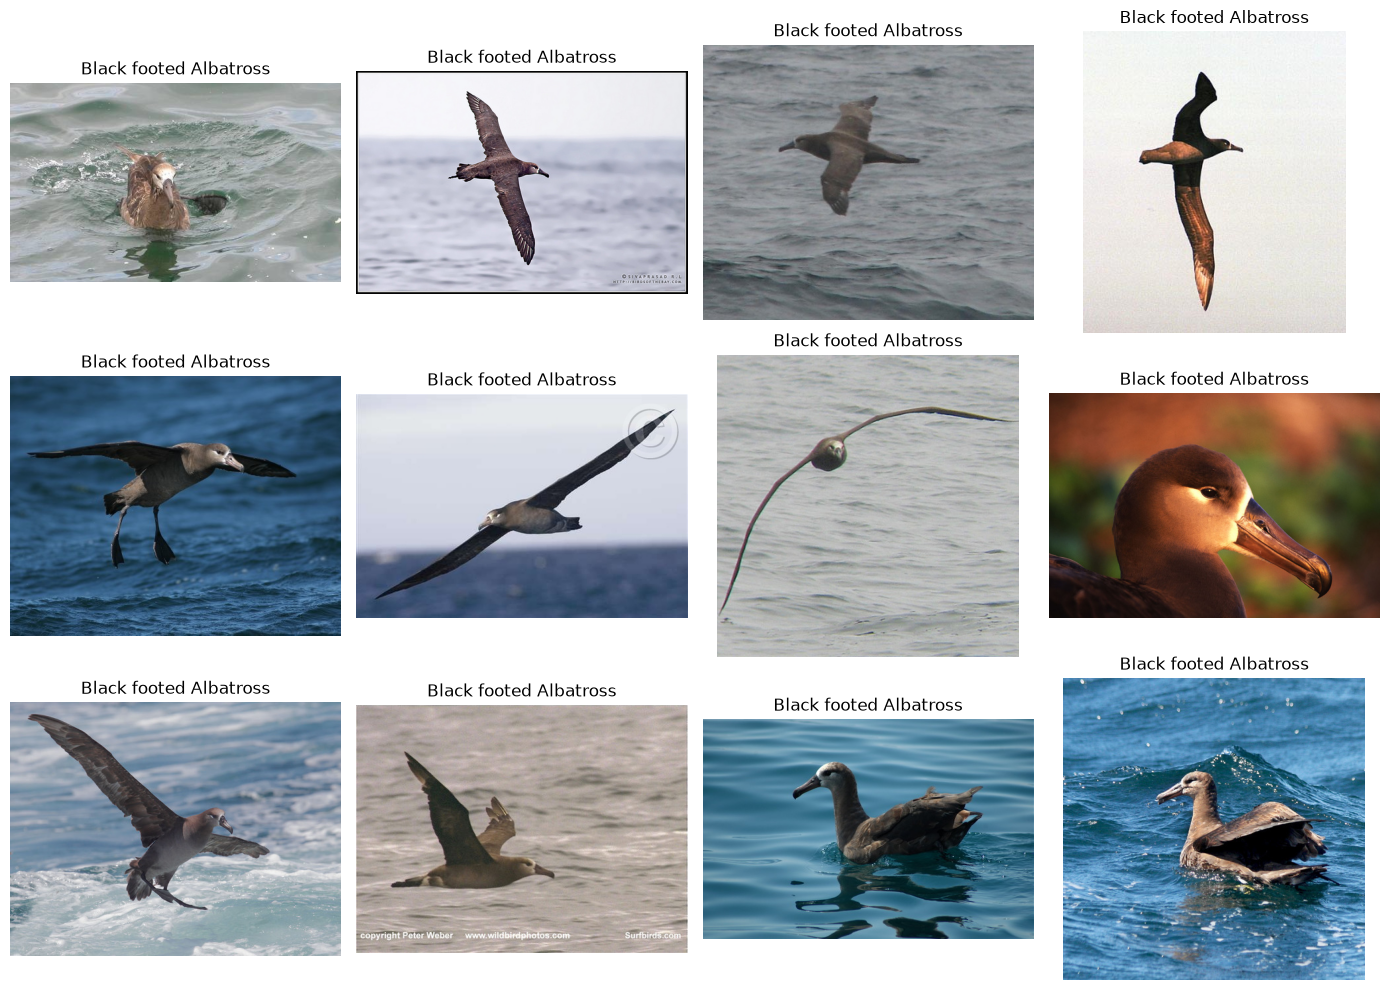

In [23]:
num_images = min(12, len(train_dataset))

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for i in range(num_images):
    sample = train_dataset[i]
    img = sample["image"]
    label = sample["label"]

    axes[i].imshow(img)
    axes[i].set_title(class_names[label])
    axes[i].axis("off")

for i in range(num_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

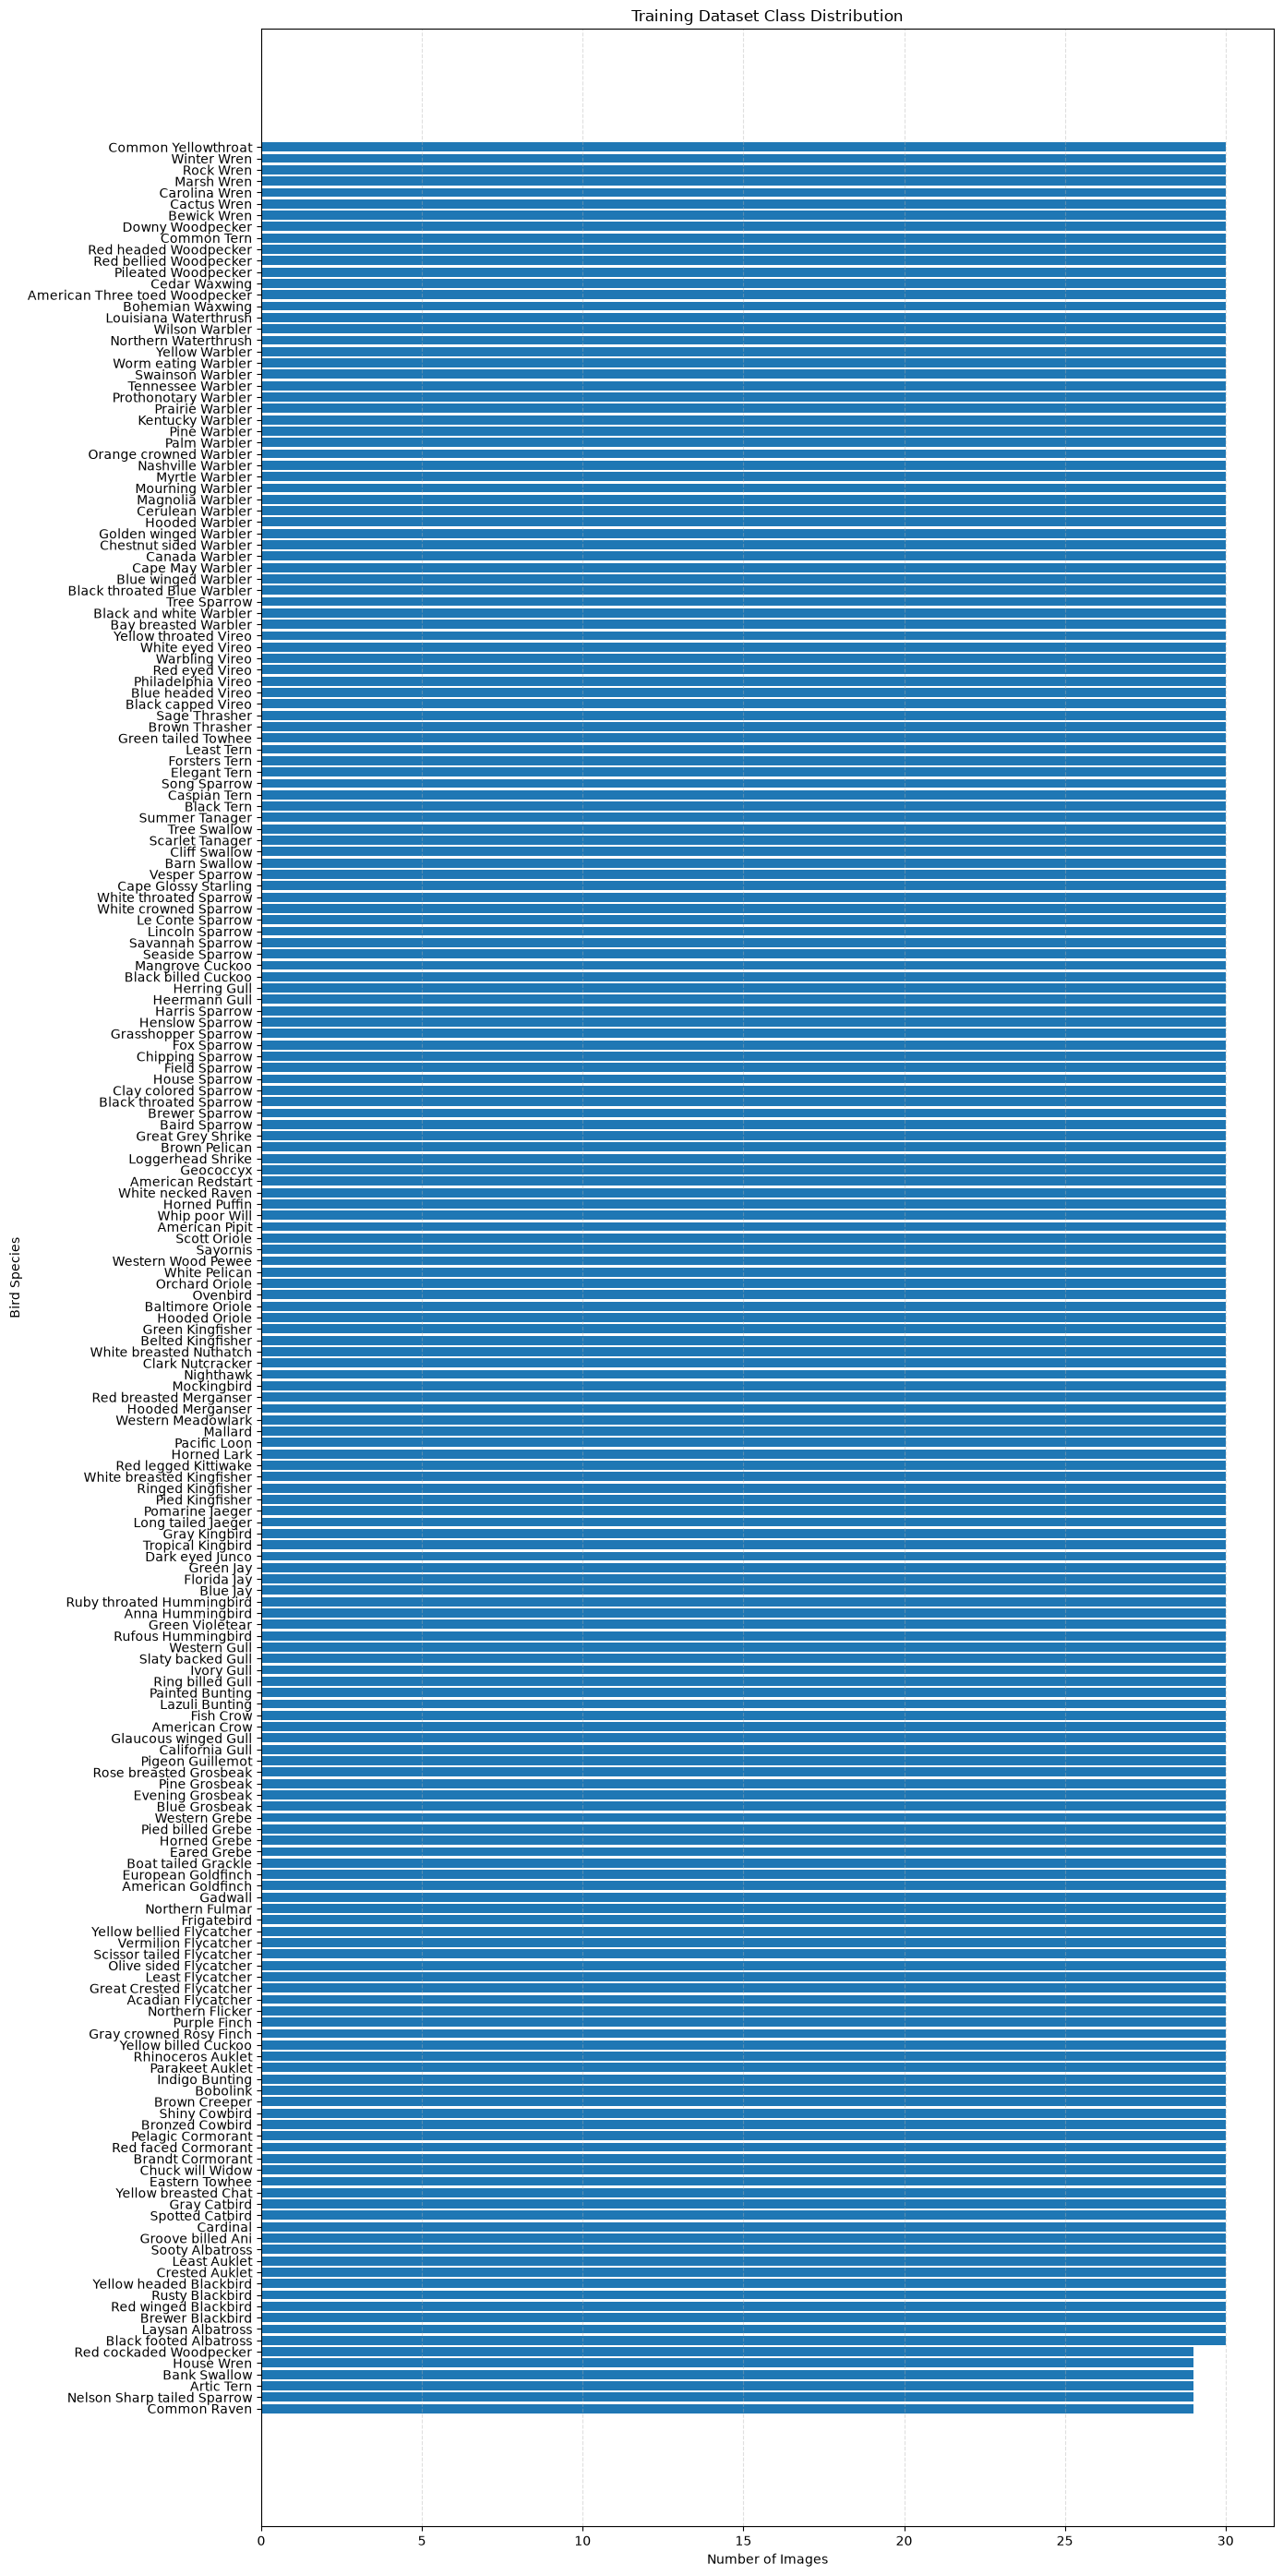

In [ ]:



# Sort species by label order
train_plot = class_distribution.sort_values(
    "train_count", ascending=True
)

plt.figure(figsize=(14, 28))

plt.barh(
    train_plot["species"],
    train_plot["train_count"]
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Number of Images")
plt.ylabel("Bird Species")

plt.xticks(range(0, int(train_plot["train_count"].max()) + 2, 5))
plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


In [ ]:
# Note that this checks whether the images can be accessed and have valid dimensions
image_stats = []

for idx, sample in enumerate(train_dataset):
    try:
        img = sample["image"]

        if img is None:
            raise ValueError("Image is None")

        width, height = img.size

        if width <= 0 or height <= 0:
            raise ValueError("Invalid image dimensions")

        image_stats.append({
            "index": idx,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "mode": img.mode,
            "format": img.format,
            "valid": True
        })

    except Exception as e:
        image_stats.append({
            "index": idx,
            "width": None,
            "height": None,
            "aspect_ratio": None,
            "mode": None,
            "format": None,
            "valid": False
        })

image_df = pd.DataFrame(image_stats)

print("Total images:", len(image_df))
print("Valid images:", image_df["valid"].sum())
print("Invalid images:", (~image_df["valid"]).sum())

Total images: 5994
Valid images: 5994
Invalid images: 0


In [21]:
valid_images = image_df[image_df["valid"]].copy()

print("Width statistics:")
print(valid_images["width"].describe())

print("\nHeight statistics:")
print(valid_images["height"].describe())

print("\nAspect ratio statistics:")
print(valid_images["aspect_ratio"].describe())

print("\nColor modes:")
print(valid_images["mode"].value_counts())

print("\nImage formats:")
print(valid_images["format"].value_counts())

Width statistics:
count    5994.000000
mean      467.618952
std        64.524346
min       121.000000
25%       492.000000
50%       500.000000
75%       500.000000
max       500.000000
Name: width, dtype: float64

Height statistics:
count    5994.000000
mean      386.253587
std        70.961752
min       120.000000
25%       333.000000
50%       375.000000
75%       435.000000
max       500.000000
Name: height, dtype: float64

Aspect ratio statistics:
count    5994.000000
mean        1.255362
std         0.287376
min         0.488000
25%         1.066668
50%         1.333333
75%         1.497006
max         3.597122
Name: aspect_ratio, dtype: float64

Color modes:
mode
RGB    5990
L         4
Name: count, dtype: int64

Image formats:
format
JPEG    5502
Name: count, dtype: int64


In [29]:

for idx in range(min(5, len(train_dataset))):
    try:
        img = train_dataset[idx]["image"]

        print(f"\nImage {idx}")
        print("Image type:", type(img))

        rgb = np.array(img.convert("RGB"))
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        print("Image size:", img.size)
        print("Sharpness:", sharpness)

    except Exception as e:
        print(f"Error for image {idx}: {type(e).__name__}: {e}")



Image 0
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (500, 301)
Sharpness: 811.4553238509951

Image 1
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (500, 336)
Sharpness: 1509.2446215884

Image 2
Image type: <class 'PIL.Image.Image'>
Image size: (500, 416)
Sharpness: 70.62497570673077

Image 3
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (331, 380)
Sharpness: 447.1826583227988

Image 4
Image type: <class 'PIL.JpegImagePlugin.JpegImageFile'>
Image size: (500, 392)
Sharpness: 315.88161697831634


In [30]:


quality_stats = []

for idx, sample in enumerate(train_dataset):
    try:
        img = sample["image"]

        if img is None:
            raise ValueError("Missing image")

        # Convert PIL image to RGB
        rgb = np.array(img.convert("RGB"))

        # Convert RGB to grayscale for sharpness and brightness
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

        height, width = gray.shape

        # Laplacian variance: lower values can indicate blur
        sharpness = cv2.Laplacian(
            gray, cv2.CV_64F
        ).var()

        # Average grayscale intensity
        brightness = gray.mean()

        # Standard deviation indicates intensity variation
        contrast = gray.std()

        quality_stats.append({
            "index": idx,
            "width": width,
            "height": height,
            "resolution": width * height,
            "sharpness": sharpness,
            "brightness": brightness,
            "contrast": contrast,
            "valid": True
        })

    except Exception as e:
        quality_stats.append({
            "index": idx,
            "width": None,
            "height": None,
            "resolution": None,
            "sharpness": None,
            "brightness": None,
            "contrast": None,
            "valid": False
        })

quality_df = pd.DataFrame(quality_stats)

print("Total images:", len(quality_df))
print("Failed image checks:", (~quality_df["valid"]).sum())

display(
    quality_df.loc[quality_df["valid"]].describe().round(2)
)


Total images: 5994
Failed image checks: 0


,index,width,height,resolution,sharpness,brightness,contrast
count,5994.00,5994.00,5994.00,5994.00,5994.00,5994.00,5994.00
mean,2996.50,467.62,386.25,179397.96,1400.23,124.35,45.36
std,1730.46,64.52,70.96,32166.73,1965.04,32.02,14.22
min,0.00,121.00,120.00,19460.00,7.97,20.98,9.70
25%,1498.25,492.00,333.00,166500.00,410.21,103.91,34.98
50%,2996.50,500.00,375.00,178500.00,817.31,123.26,44.29
75%,4494.75,500.00,435.00,195000.00,1637.49,144.09,54.42
max,5993.00,500.00,500.00,250000.00,53215.03,244.11,106.25


In [31]:

print("Width range:", quality_df["width"].min(),
      "to", quality_df["width"].max())

print("Height range:", quality_df["height"].min(),
      "to", quality_df["height"].max())

print("Invalid images:", (~quality_df["valid"]).sum())

print("\nImages with the smallest sharpness values:")
display(
    quality_df.nsmallest(10, "sharpness")[
        ["index", "width", "height", "sharpness",
         "brightness", "contrast", "valid"]
    ]
)


Width range: 121 to 500
Height range: 120 to 500
Invalid images: 0

Images with the smallest sharpness values:


,index,width,height,sharpness,brightness,contrast,valid
4091,4091,500,300,7.965320,123.144620,19.045449,True
4332,4332,500,354,17.064890,74.440746,56.783161,True
483,483,500,333,17.589545,77.090547,20.212791,True
5293,5293,500,375,20.232558,78.600816,16.114112,True
1315,1315,500,375,21.169707,137.564784,15.299324,True
1335,1335,500,333,23.487770,164.251123,34.700197,True
5703,5703,464,397,27.713979,152.418777,54.405914,True
2094,2094,485,441,28.567692,68.716974,18.557813,True
2529,2529,500,428,28.973164,194.787112,22.910640,True
4235,4235,400,500,29.933860,173.240245,33.335348,True
